In [1]:
import numpy as np
from matplotlib import pyplot as plt
import pickle
import pandas as pd

## Important Function

In [2]:
class Data:
    def __init__(self, array_list):
        self.array_list = array_list

    def save(self, filename):
        with open(filename, 'wb') as f:
            pickle.dump(self.array_list, f)

    @classmethod
    def load(cls, filename):
        with open(filename, 'rb') as f:
            array_list = pickle.load(f)
        return cls(array_list)

## Plain MD

In [3]:
plain_md_path = '../Plain_MD/analysis'

## Load the error from MSM

df_stationary_p = pd.read_csv(f"{plain_md_path}/autocoorel_data/trans_population_at_lagtime_8conform.csv")


# Pivot the DataFrame to reshape it
pivot_mean = df_stationary_p.pivot(index='thermo_state', columns='conform_state', values='mean')
pivot_std = df_stationary_p.pivot(index='thermo_state', columns='conform_state', values='std')

# Convert to NumPy arrays
plain_md_refer_array = pivot_mean.to_numpy()  # shape (1, 8) state, residues 
plain_md_refer_err_array = pivot_std.to_numpy()  # shape (1, 8)
df_stationary_p

,thermo_state,conform_state,mean,std,lagtime_ns
0,0,0,0.073024,0.012240,10.0
1,0,1,0.082322,0.009419,10.0
2,0,2,0.060915,0.010660,10.0
3,0,3,0.061086,0.007271,10.0
4,0,4,0.170299,0.032696,10.0
5,0,5,0.236294,0.016833,10.0
6,0,6,0.150493,0.023422,10.0
7,0,7,0.165567,0.020853,10.0


In [4]:
plain_md_path = '../Plain_MD/analysis'


population_loaded = Data.load(f"{plain_md_path}/population_data/population_8_conform_reduced.pkl").array_list
population_mean = population_loaded[0]
population_std = population_loaded[1]

plain_md_population_mean = population_mean
plain_md_population_std = population_std
plain_md_population_mean.shape

(8, 48230)

## EE

In [5]:
## Load in the refer data 

ee_path = '../EE/analysis'

df_stationary_p = pd.read_csv(f"{ee_path}/autocoorel_data/trans_population_at_lagtime_8conforms.csv")

    
# Pivot the DataFrame to reshape it
pivot_mean = df_stationary_p.pivot(index='thermo_state', columns='conform_state', values='mean')
pivot_std = df_stationary_p.pivot(index='thermo_state', columns='conform_state', values='std')

# Convert to NumPy arrays
ee_refer_array = pivot_mean.to_numpy()  # shape (6, 3) state, residues 
ee_refer_err_array = pivot_std.to_numpy()  # shape (6, 3)
ee_refer_array.shape

(4, 8)

In [6]:
ee_path = '../EE/analysis'

population_loaded = Data.load(f"{ee_path}/population_data/population_8_conform.pkl").array_list
population_mean = population_loaded[0]
population_std = population_loaded[1]

ee_population_mean = population_mean
ee_population_std = population_std
ee_population_mean.shape

(4, 8, 318010)

## HREX

In [7]:
hrex_path = '../HREX/analysis'

df_stationary_p = pd.read_csv(f"{hrex_path}/autocoorel_data/trans_population_at_lagtime_8conforms.csv")
#     
# Pivot the DataFrame to reshape it
pivot_mean = df_stationary_p.pivot(index='thermo_state', columns='conform_state', values='mean')
pivot_std = df_stationary_p.pivot(index='thermo_state', columns='conform_state', values='std')

# Convert to NumPy arrays
hrex_trans_refer_array = pivot_mean.to_numpy()  # shape (6, 3) state, residues
hrex_trans_refer_err_array = pivot_std.to_numpy()  # shape (6, 3)
hrex_trans_refer_array.shape

#df_stationary_p

(6, 8)

In [8]:
hrex_path = '../HREX/analysis'


population_loaded = Data.load(f"{hrex_path}/population_data/population_8_conform.pkl").array_list
population_mean = population_loaded[0]
hrex_population_mean = population_mean
hrex_population_mean.shape

(6, 8, 600030)

## REDs

In [9]:
reds_path = '../REDs/analysis'
df_stationary_p = pd.read_csv(f"{reds_path}/autocoorel_data/trans_population_at_lagtime_8conforms.csv")

# Pivot the DataFrame to reshape it
pivot_mean = df_stationary_p.pivot(index='thermo_state', columns='conform_state', values='mean')
pivot_std = df_stationary_p.pivot(index='thermo_state', columns='conform_state', values='std')

# Convert to NumPy arrays
reds_trans_refer_array = pivot_mean.to_numpy()  # shape (6, 3) state, residues 
reds_trans_refer_err_array = pivot_std.to_numpy()  # shape (6, 3)
reds_trans_refer_err_array.shape

#df_stationary_p

(3, 8)

In [10]:
reds_path = '../REDs/analysis'


population_loaded = Data.load(f"{reds_path}/population_data/population_8_conform_reduced.pkl").array_list
population_mean = population_loaded[0]

reds_population_mean = population_mean
reds_population_mean.shape

(3, 8, 33752)

## Metadynamics

In [11]:
def load_individual_trajectory(filename):
    """Load a single trajectory from pickle file - no changes needed"""
    with open(filename, 'rb') as f:
        data = pickle.load(f)
    
    print(f"Loaded trajectory: {data['metadata']['trajectory_name']}")
    print(f"  Frame count: {data['metadata']['frame_count']}")
    print(f"  Parameters: {data['metadata']['parameters']}")
    
    return data

def load_convergence_data(filename):
    """Load convergence data from pickle file"""
    with open(filename, 'rb') as f:
        data = pickle.load(f)
    
    print("Loaded data summary:")
   # print(f"  Timestamp: {data['metadata']['timestamp']}")
    print(f"  Number of walkers: {data['metadata']['n_walkers']}")
    print(f"  Total frames per walker: {data['metadata']['walker_frame_counts']}")
    print(f"  Parameters: {data['metadata']['parameters']}")
    
    return data

In [12]:
metadynamics_path = '../Metadynamics/analysis'

### omg8rep

In [13]:
metadynamics_path = '../Metadynamics/analysis'
STATE_ORDER_ALPHA = ['CCC','CCT','CTC','CTT','TCC','TCT','TTC','TTT']

# NOTE: previously this reference came from an MSM (transition-matrix) stationary
# distribution, which is not valid for a metadynamics-biased trajectory. It is now
# the late-block, bias-reweighted population from the 8-replica omega ensemble
# (see Metadynamics/analysis/omega_state_analysis/).
omg8rep_late = pd.read_csv(f"{metadynamics_path}/omega_state_analysis/state_analysis_results/all_replicas_late_population_average.csv").set_index("state").reindex(STATE_ORDER_ALPHA)

omg8rep_trans_refer_array = omg8rep_late["population"].to_numpy()
omg8rep_trans_refer_err_array = omg8rep_late["population_sem_across_replicas"].to_numpy()

omg8rep_late

,population,population_std_across_replicas,population_sem_across_replicas,biased_population,n_replicas,free_energy,delta_free_energy,biased_free_energy,biased_delta_free_energy
state,,,,,,,,,
CCC,0.078720,0.033281,0.011767,0.083343,8,6.340258,2.686402,6.197904,2.121829
CCT,0.094911,0.036529,0.012915,0.102731,8,5.873706,2.219851,5.676218,1.600143
CTC,0.063526,0.026146,0.009244,0.079596,8,6.875147,3.221292,6.312652,2.236577
CTT,0.067779,0.026914,0.009516,0.080478,8,6.713527,3.059671,6.285169,2.209094
TCC,0.155340,0.046125,0.016308,0.141628,8,4.644806,0.990951,4.875314,0.799239
TCT,0.231110,0.079364,0.028059,0.195122,8,3.653856,0.000000,4.076075,0.000000
TTC,0.137816,0.033526,0.011853,0.149606,8,4.943368,1.289512,4.738620,0.662545
TTT,0.170797,0.027504,0.009724,0.167496,8,4.408189,0.754333,4.456874,0.380799


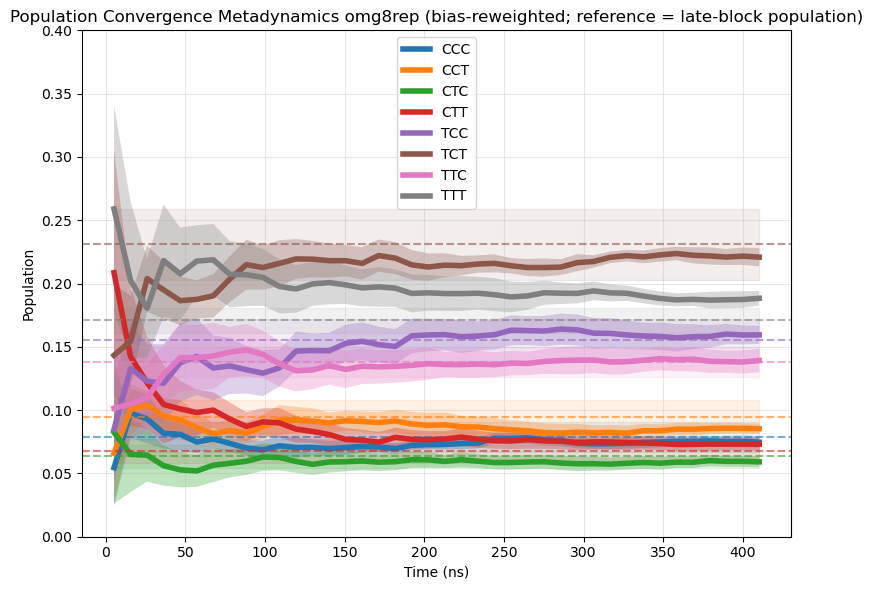

In [14]:
# Population-over-time curve, from the same bias-reweighted ensemble analysis
# (Metadynamics/analysis/omega_state_analysis/ensemble_cumulative_populations_start0.csv)
# instead of the old un-reweighted windowed-population pickle.
omg8rep_cum = pd.read_csv(f"{metadynamics_path}/omega_state_analysis/state_analysis_results/ensemble_cumulative_populations_start0.csv")

omg_population_mean = np.array([
    omg8rep_cum[omg8rep_cum["state"] == s].sort_values("block")["population"].to_numpy()
    for s in STATE_ORDER_ALPHA
])
omg_population_std = np.array([
    omg8rep_cum[omg8rep_cum["state"] == s].sort_values("block")["population_sem"].to_numpy()
    for s in STATE_ORDER_ALPHA
])
omg_times_ns = omg8rep_cum[omg8rep_cum["state"] == STATE_ORDER_ALPHA[0]].sort_values("block")["midpoint_time"].to_numpy() / 1000.0

omg8rep_meta_data = {
    'metadata': {'parameters': {'dt': 1.0}},
    'averaged_convergence': {'frames': omg_times_ns.tolist()},
}

plt.figure(figsize=(8, 6))
for i, state in enumerate(STATE_ORDER_ALPHA):
    pops = omg_population_mean[i]
    errors = omg_population_std[i]
    plt.plot(omg_times_ns, pops, label=state, linewidth=4)
    plt.fill_between(omg_times_ns, pops - errors, pops + errors, alpha=0.3)

    # Reference horizontal line: late-block population (bias-reweighted), not MSM
    ref_y = omg8rep_trans_refer_array[i]
    ref_yerr = omg8rep_trans_refer_err_array[i]
    plt.axhline(y=ref_y, linestyle='--', color=f'C{i}', alpha=0.6)
    plt.fill_between(omg_times_ns, [ref_y - ref_yerr] * len(omg_times_ns), [ref_y + ref_yerr] * len(omg_times_ns),
                     color=f'C{i}', alpha=0.1)

plt.xlabel('Time (ns)')
plt.ylabel('Population')
plt.title('Population Convergence Metadynamics omg8rep (bias-reweighted; reference = late-block population)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.ylim(0, 0.4)

plt.tight_layout()
plt.show()

### oppc8rep

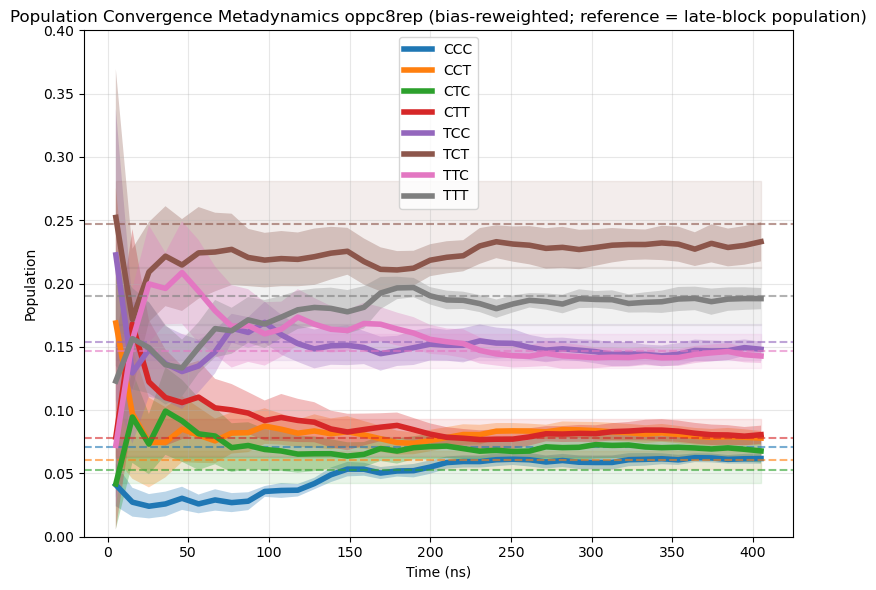

In [15]:
# oppc8rep: same treatment as omg8rep above (late-block reference + bias-reweighted
# population-over-time curve, replacing the old MSM reference / un-reweighted pickle).
oppc8rep_late = pd.read_csv(f"{metadynamics_path}/oppc_state_analysis/state_analysis_results/all_replicas_late_population_average.csv").set_index("state").reindex(STATE_ORDER_ALPHA)
oppc8rep_trans_refer_array = oppc8rep_late["population"].to_numpy()
oppc8rep_trans_refer_err_array = oppc8rep_late["population_sem_across_replicas"].to_numpy()

oppc8rep_cum = pd.read_csv(f"{metadynamics_path}/oppc_state_analysis/state_analysis_results/ensemble_cumulative_populations_start0.csv")

oppc_population_mean = np.array([
    oppc8rep_cum[oppc8rep_cum["state"] == s].sort_values("block")["population"].to_numpy()
    for s in STATE_ORDER_ALPHA
])
oppc_population_std = np.array([
    oppc8rep_cum[oppc8rep_cum["state"] == s].sort_values("block")["population_sem"].to_numpy()
    for s in STATE_ORDER_ALPHA
])
oppc_times_ns = oppc8rep_cum[oppc8rep_cum["state"] == STATE_ORDER_ALPHA[0]].sort_values("block")["midpoint_time"].to_numpy() / 1000.0

oppc8rep_meta_data = {
    'metadata': {'parameters': {'dt': 1.0}},
    'averaged_convergence': {'frames': oppc_times_ns.tolist()},
}

plt.figure(figsize=(8, 6))
for i, state in enumerate(STATE_ORDER_ALPHA):
    pops = oppc_population_mean[i]
    errors = oppc_population_std[i]
    plt.plot(oppc_times_ns, pops, label=state, linewidth=4)
    plt.fill_between(oppc_times_ns, pops - errors, pops + errors, alpha=0.3)

    ref_y = oppc8rep_trans_refer_array[i]
    ref_yerr = oppc8rep_trans_refer_err_array[i]
    plt.axhline(y=ref_y, linestyle='--', color=f'C{i}', alpha=0.6)
    plt.fill_between(oppc_times_ns, [ref_y - ref_yerr] * len(oppc_times_ns), [ref_y + ref_yerr] * len(oppc_times_ns),
                     color=f'C{i}', alpha=0.1)

plt.xlabel('Time (ns)')
plt.ylabel('Population')
plt.title('Population Convergence Metadynamics oppc8rep (bias-reweighted; reference = late-block population)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.ylim(0, 0.4)

plt.tight_layout()
plt.show()

### Single-replica PBMetaD CV variants (META-OPH/META-OPP/META-OPPC)

Loaded here (rather than only in the SI section below) so the three
single-replica CV variants can also be folded into the one combined,
all-methods `methods` dict/plot below -- this project's convention is one
comprehensive graph per analysis type with every method overlaid, not a
separate main-methods graph plus a metadynamics-only side figure.

In [16]:
# Bias-reweighted population-over-time + late-block reference for the three
# single-replica PBMetaD CV variants, from the single-long-trajectory outputs
# (same pipeline as META-OMG8REP/META-OPPC8REP above, just single-trajectory).
SINGLE_TRAJ_DIR = f"{metadynamics_path}/single_trajectory_state_analysis"
SINGLE_CV_FOLDERS = {"META-OPH": "ophi", "META-OPP": "ophps", "META-OPPC": "oppc"}


def load_single_traj_cv_population(folder):
    late = pd.read_csv(f"{SINGLE_TRAJ_DIR}/{folder}/{folder}_late_state_summary.csv").set_index("state").reindex(STATE_ORDER_ALPHA)
    cum = pd.read_csv(f"{SINGLE_TRAJ_DIR}/{folder}/{folder}_cumulative_state_free_energies.csv")
    times_ns = cum[cum["state"] == STATE_ORDER_ALPHA[0]].sort_values("block")["midpoint_time"].to_numpy() / 1000.0
    means = np.array([
        cum[cum["state"] == s].sort_values("block")["population"].to_numpy() for s in STATE_ORDER_ALPHA
    ])
    return {
        "times": times_ns,
        "means": means,
        "ref_mean": late["population"].to_numpy(),
        "ref_err": late["population_std_across_blocks"].to_numpy(),
    }


single_replica_meta_pop = {name: load_single_traj_cv_population(folder) for name, folder in SINGLE_CV_FOLDERS.items()}
{name: d["means"].shape for name, d in single_replica_meta_pop.items()}

{'META-OPH': (8, 40), 'META-OPP': (8, 40), 'META-OPPC': (8, 40)}

## Combined Plot 

In [17]:
conformation_list = [
    'ccc','cct','ctc','ctt',
    'tcc','tct','ttc','ttt'
]

In [18]:
methods = {
    "Plain MD": {
        "mean": plain_md_population_mean,
        "std": plain_md_population_std,
        "ref": plain_md_refer_array,
        "ref_err": plain_md_refer_err_array,
        "dt": 0.1,  # ns
        "shape": "2d"
    },
    "EE": {
        "mean": ee_population_mean[0],
        "std": ee_population_std[0],
        "ref": ee_refer_array[0],
        "ref_err": ee_refer_err_array[0],
        "dt": 0.01,
        "shape": "2d"
    },
    "HREX": {
        "mean": hrex_population_mean[0],
        "std": None,
        "ref": hrex_trans_refer_array[0],
        "ref_err": hrex_trans_refer_err_array[0],
        "dt": 0.01,
        "shape": "2d"
    },
    "REDS": {
        "mean": reds_population_mean[0],
        "std": None,
        "ref": reds_trans_refer_array[0],
        "ref_err": reds_trans_refer_array[0],
        "dt": 0.04,
        "shape": "2d"
    },
    "META-OMG8REP": {
        "mean": omg_population_mean,
        "std": omg_population_std,
        "ref": None,
        "ref_err": None,
        "dt": omg8rep_meta_data['metadata']['parameters']['dt'],  # e.g., 0.002 ns
        "frames": omg8rep_meta_data['averaged_convergence']['frames'],
        "shape": "1d"
    },
    "META-OPPC8REP": {
        "mean": oppc_population_mean[:,:205],
        "std": oppc_population_std[:,:205],
        "ref": None,
        "ref_err": None,
        "dt": oppc8rep_meta_data['metadata']['parameters']['dt'],
        "frames": oppc8rep_meta_data['averaged_convergence']['frames'],
        "shape": "1d"
    },
}

# Single-replica PBMetaD CV variants: same "1d" shape (explicit "frames" in ns,
# dt=1.0), no std band over time (no replicate spread), but do carry their own
# late-block "ref"/"ref_err" -- unlike the two 8REP entries above, whose
# reference is instead drawn directly in the SI section below via meta_refs.
for _name, _data in single_replica_meta_pop.items():
    methods[_name] = {
        "mean": _data["means"],
        "std": None,
        "ref": _data["ref_mean"],
        "ref_err": _data["ref_err"],
        "dt": 1.0,
        "frames": _data["times"].tolist(),
        "shape": "1d",
    }


In [19]:
# --- Shared setup + helper for the "combine plot" grids below ---
from plotting_style import (
    METHOD_COLORS, TITLE_FONTSIZE, TICK_FONTSIZE, AXIS_LABEL_FONTSIZE,
    LEGEND_FONTSIZE, LINEWIDTH, style_panel, add_grid_legend,
)

method_colors = METHOD_COLORS


def plot_population_grid(methods_subset, savepath, skip_methods=(), figsize=(12, 6), dpi=300, fontscale=1.0):
    fig, axes = plt.subplots(2, 4, figsize=figsize, sharex=True, sharey=True)
    axes = axes.flatten()

    for conform in range(len(conformation_list)):
        ax = axes[conform]
        for method, data in methods_subset.items():
            if method in skip_methods:
                continue
            if data["shape"] == "2d":
                T = data["mean"].shape[1]
                time_vals = np.arange(T) * data["dt"]
            else:
                time_vals = np.array(data["frames"]) * data["dt"]
            mean_vals = data["mean"][conform]
            std_vals = data["std"][conform] if data["std"] is not None else None

            color = method_colors.get(method, "#333333")
            ax.plot(time_vals, mean_vals, linestyle='-', markersize=3, label=method,
                     color=color, linewidth=LINEWIDTH)
            if std_vals is not None:
                ax.fill_between(time_vals, mean_vals - std_vals, mean_vals + std_vals,
                                  alpha=0.1, color=color, linewidth=0)

        style_panel(ax, conformation_list[conform],
                    tick_fontsize=TICK_FONTSIZE * fontscale, title_fontsize=TITLE_FONTSIZE * fontscale)
        ax.set_ylim(0, 0.3)
        ax.set_xlim(1, 10000)  # start at 1 for log scale to avoid log(0)
        ax.set_xscale("log")

    fig.supxlabel(r'$\tau$ (ns)', fontsize=AXIS_LABEL_FONTSIZE * fontscale)
    fig.supylabel("Normalized Backbone\nPopulation", fontsize=AXIS_LABEL_FONTSIZE * fontscale)
    add_grid_legend(fig, axes[0], fontsize=LEGEND_FONTSIZE * fontscale)

    plt.tight_layout(rect=[0, 0, 1, 0.93])
    plt.savefig(savepath, dpi=dpi, bbox_inches='tight')
    plt.show()

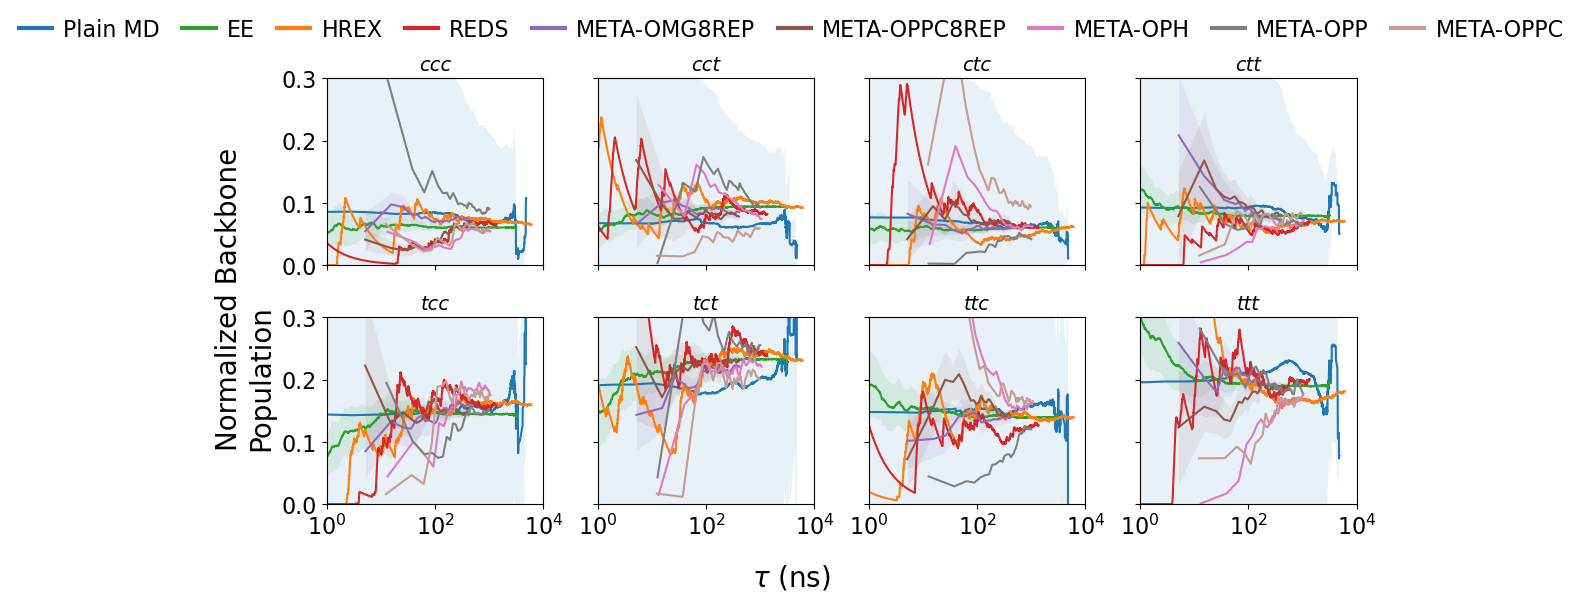

In [20]:
plot_population_grid(methods, "fig/population_over_time_all_8_conform_log_scale_combine.png")


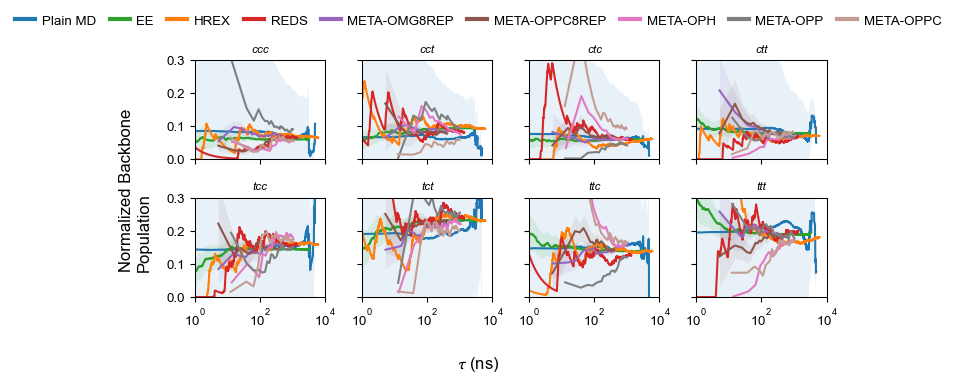

In [21]:
# --- Elsevier style: double-column width (190 mm / 7.48 in), Guide for Authors ---
import os
os.makedirs('fig_elsevier', exist_ok=True)

ELSEVIER_RC = {
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'mathtext.fontset': 'stixsans',
    'axes.linewidth': 0.75,
    'xtick.direction': 'out',
    'ytick.direction': 'out',
}

# Raster PNG, not vector PDF: at this data density a vector export balloons to
# tens of MB - the fig/ version of this same dense-curve plot uses PNG too.
# fontscale keeps text legible without overflowing the narrower canvas.
with plt.rc_context(ELSEVIER_RC):
    plot_population_grid(
        methods, "fig_elsevier/population_over_time_all_8_conform_log_scale.png",
        figsize=(7.48, 3.74), dpi=600, fontscale=0.6,
    )

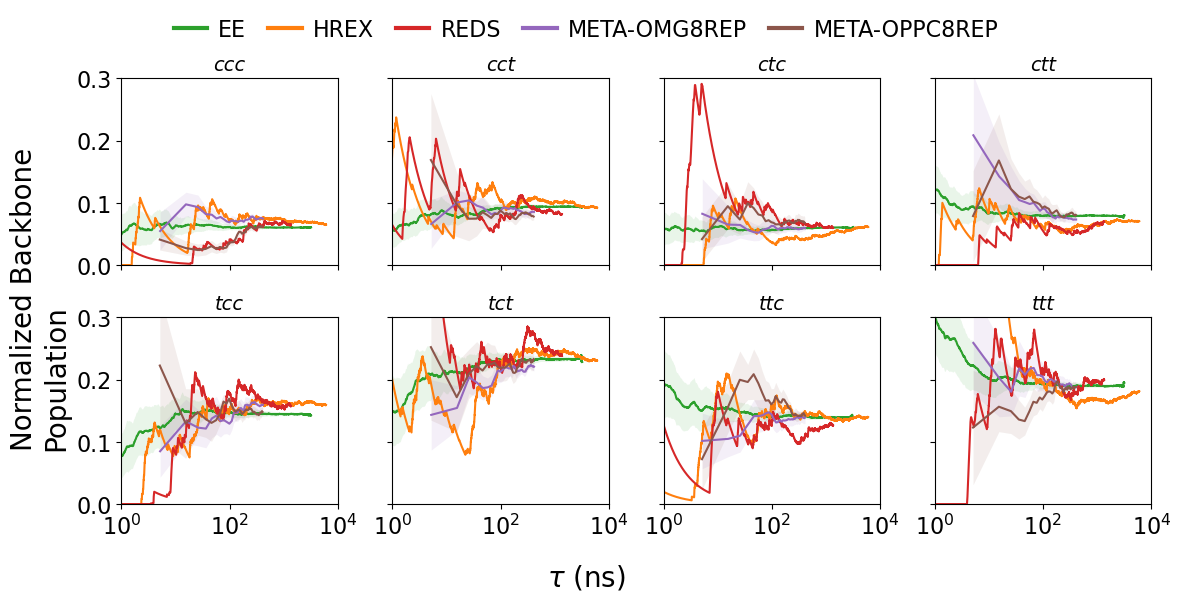

In [22]:
# Main-text figure: kept to exactly the 6 canonical methods (EE, HREX, REDS,
# META-OMG8REP, META-OPPC8REP) -- ANALYSIS_RULES.md Sec. 5 explicitly says
# META-OPH/META-OPP (and, by the same logic, the single-replica META-OPPC) are
# SI-only and must not be added into main-text-style comparison figures.
plot_population_grid(
    methods, "fig/main_population_over_time_all_8_conform_log_scale_esms.png",
    skip_methods=("Plain MD", "META-OPH", "META-OPP", "META-OPPC"),
)


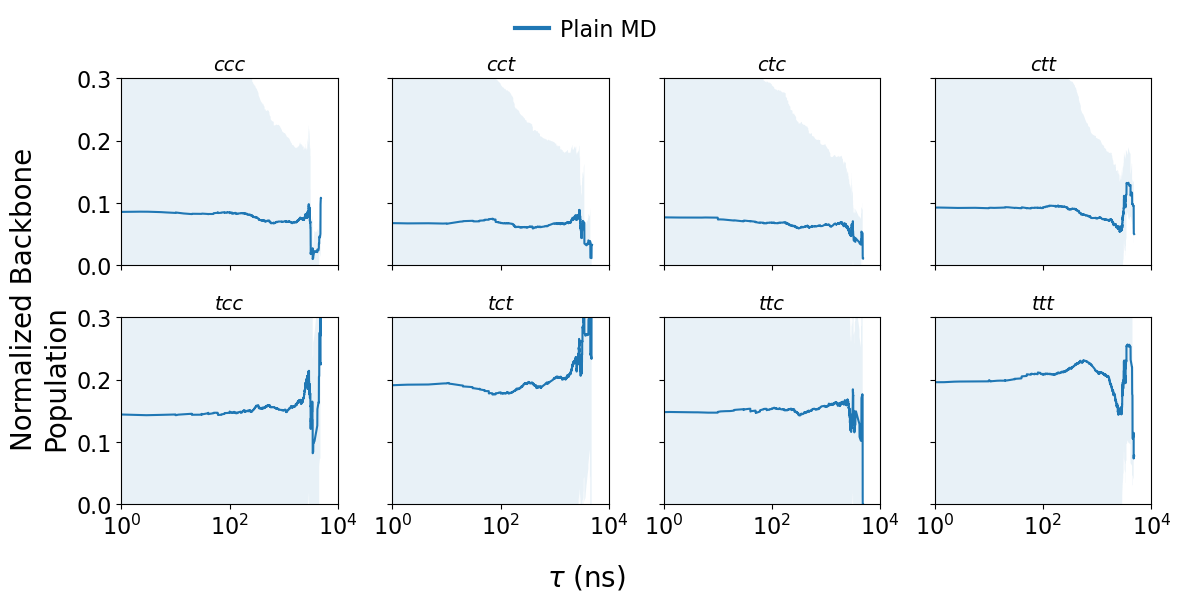

In [23]:
plot_population_grid(
    {"Plain MD": methods["Plain MD"]}, "fig/main_population_over_time_all_8_conform_log_scale_plainmd.png",
)


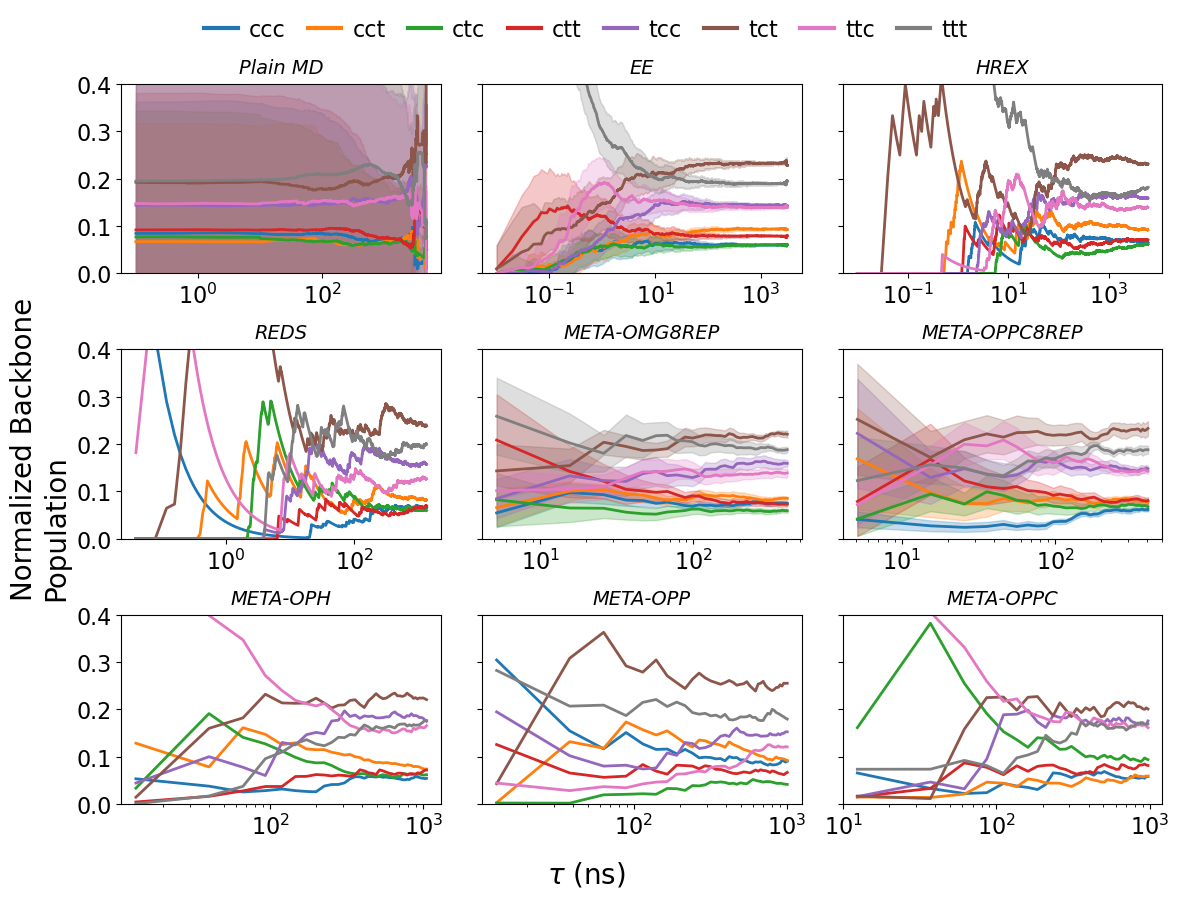

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from plotting_style import TITLE_FONTSIZE, TICK_FONTSIZE, AXIS_LABEL_FONTSIZE, add_grid_legend

ncols = 3
nrows = -(-len(methods) // ncols)  # now 9 methods (was 6) since the single-replica PBMetaD CVs were folded in above
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3 * nrows), sharey=True)
axes = axes.flatten()

for idx, (method, data) in enumerate(methods.items()):
    ax = axes[idx]

    conform_num = data["mean"].shape[0]

    for conform in range(conform_num):
        # Time axis
        if data["shape"] == "2d":
            T = data["mean"].shape[1]
            time = np.arange(T) * data["dt"]
            mean = data["mean"][conform]
            std = data["std"][conform] if data["std"] is not None else None
        else:  # "1d" (Metadyn data with explicit frames)
            time = np.array(data["frames"]) * data["dt"]
            mean = np.array(data["mean"][conform])
            std = np.array(data["std"][conform]) if data["std"] is not None else None

        # Skip frame 0 if time = 0 (for log-scale safety)
        if time[0] == 0:
            time = time[1:]
            mean = mean[1:]
            if std is not None:
                std = std[1:]

        # Plot line + uncertainty fill
        line, = ax.plot(time, mean, label=f"{conformation_list[conform]}", linewidth=2, markersize=3,
                        linestyle='-')
        if std is not None:
            ax.fill_between(time, mean - std, mean + std, alpha=0.25, color=line.get_color())

    # --- Add method subtitle ---
    ax.set_title(method, fontstyle='italic', fontsize=TITLE_FONTSIZE, pad=8)
    ax.tick_params(axis='both', which='major', labelsize=TICK_FONTSIZE)

    ax.set_ylim(0, 0.4)
    ax.set_xscale("log")

# Hide any remaining unused subplot (if methods < nrows*ncols)
for j in range(len(methods), len(axes)):
    axes[j].set_visible(False)

# Shared legend at top
add_grid_legend(fig, axes[0])

# Shared x/y labels
fig.supxlabel(r'$\tau$ (ns)', fontsize=AXIS_LABEL_FONTSIZE)
fig.supylabel("Normalized Backbone\nPopulation", fontsize=AXIS_LABEL_FONTSIZE)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("fig_acs/population_over_time_all_8_conform_by_method.png", dpi=600, bbox_inches='tight')
plt.show()

## SI variants: Plain MD/EE/HREX/REDS only, with MSM stationary-reference lines

Two SI-only figures, both restricted to Plain MD/EE/HREX/REDS (no Metadynamics,
per the SI captions) and both adding a dashed horizontal line per state marking
that method's own MSM-derived stationary reference population (`data["ref"]`,
already loaded above from each method's `trans_population_at_lagtime_8conform(s).csv`)
-- a feature `plot_population_grid` above does not draw:

- log time axis (companion to `fig/population_over_time_all_8_conform_log_scale_combine.png`
  above, but without the PBMetaD curves) -> `fig/population_over_time_all_8_conform_log_scale.png`
- linear time axis -> `fig/population_over_time_all_8_conform_plot.png`

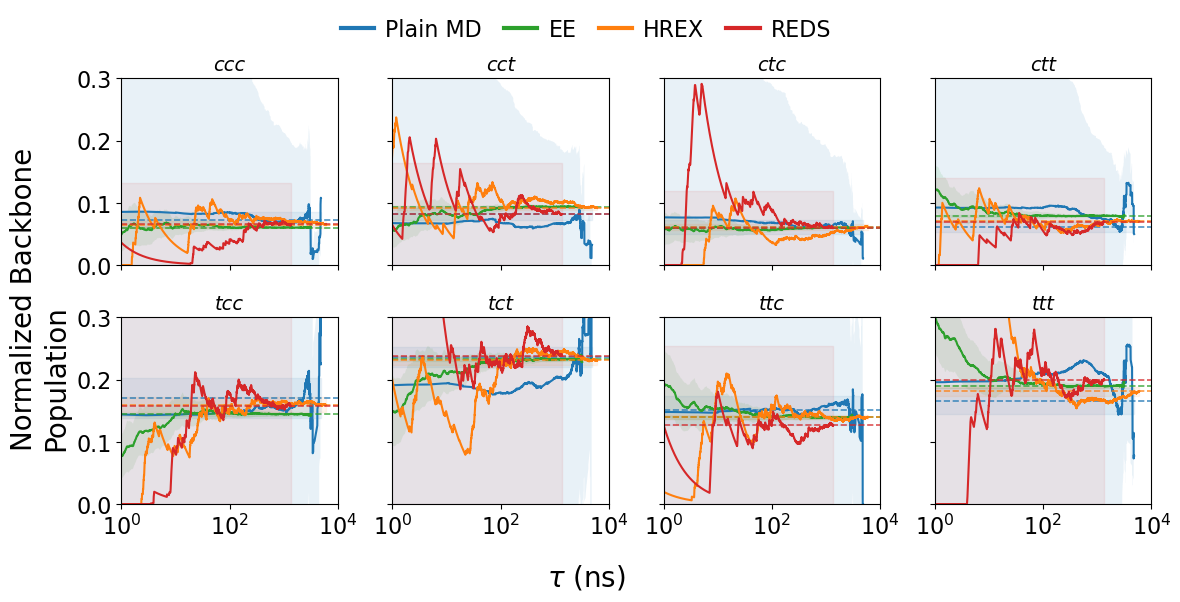

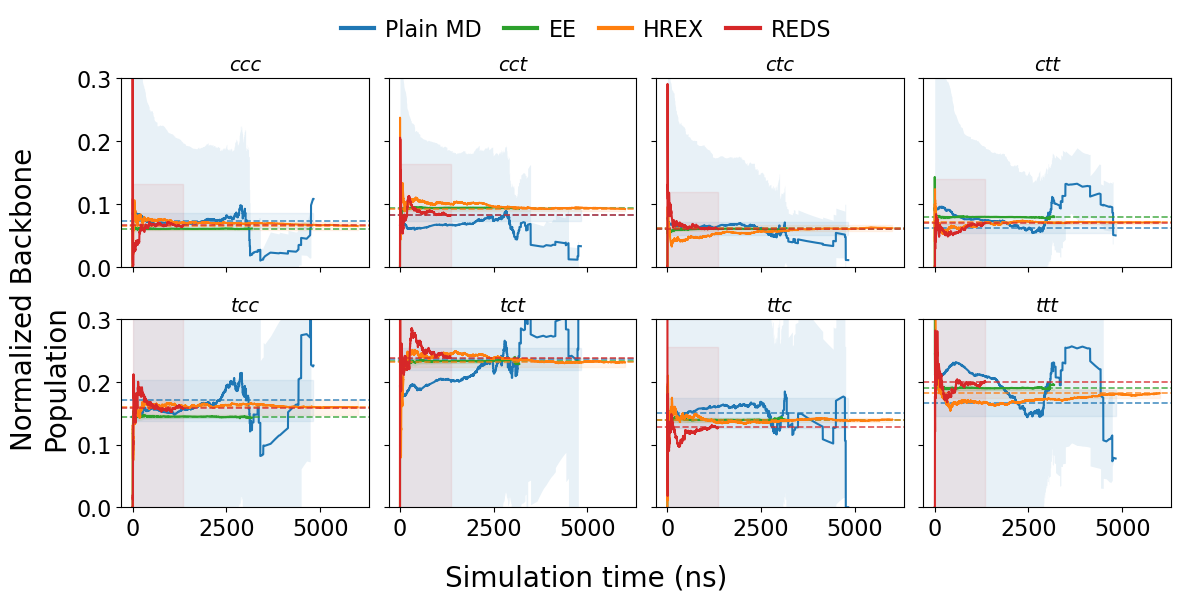

In [25]:
methods_no_meta = {k: v for k, v in methods.items() if not k.startswith("META-")}


def plot_population_grid_refs(methods_subset, savepath, xscale="log", figsize=(12, 6), dpi=300):
    fig, axes = plt.subplots(2, 4, figsize=figsize, sharex=True, sharey=True)
    axes = axes.flatten()

    for conform in range(len(conformation_list)):
        ax = axes[conform]
        for method, data in methods_subset.items():
            if data["shape"] == "2d":
                T = data["mean"].shape[1]
                time_vals = np.arange(T) * data["dt"]
            else:
                time_vals = np.array(data["frames"]) * data["dt"]
            mean_vals = data["mean"][conform]
            std_vals = data["std"][conform] if data["std"] is not None else None

            color = method_colors.get(method, "#333333")
            ax.plot(time_vals, mean_vals, linestyle='-', label=method, color=color, linewidth=LINEWIDTH)
            if std_vals is not None:
                ax.fill_between(time_vals, mean_vals - std_vals, mean_vals + std_vals,
                                 alpha=0.1, color=color, linewidth=0)

            if data.get("ref") is not None:
                # Plain MD's ref/ref_err are (1, 8) (a single thermo_state row);
                # others are already (8,) -- flatten so indexing by conform
                # always yields a scalar.
                ref_mean = np.asarray(data["ref"]).reshape(-1)[conform]
                ref_err = np.asarray(data["ref_err"]).reshape(-1)[conform]
                ax.axhline(y=ref_mean, linestyle='--', color=color, alpha=0.8, linewidth=1.2)
                ax.fill_between([time_vals.min(), time_vals.max()], [ref_mean - ref_err] * 2,
                                 [ref_mean + ref_err] * 2, color=color, alpha=0.08)

        style_panel(ax, conformation_list[conform], tick_fontsize=TICK_FONTSIZE, title_fontsize=TITLE_FONTSIZE)
        ax.set_ylim(0, 0.3)
        if xscale == "log":
            ax.set_xlim(1, 10000)
            ax.set_xscale("log")

    fig.supxlabel("Simulation time (ns)" if xscale == "linear" else r'$\tau$ (ns)', fontsize=AXIS_LABEL_FONTSIZE)
    fig.supylabel("Normalized Backbone\nPopulation", fontsize=AXIS_LABEL_FONTSIZE)
    add_grid_legend(fig, axes[0], fontsize=LEGEND_FONTSIZE)

    plt.tight_layout(rect=[0, 0, 1, 0.93])
    plt.savefig(savepath, dpi=dpi, bbox_inches='tight')
    plt.show()


plot_population_grid_refs(methods_no_meta, "fig/population_over_time_all_8_conform_log_scale.png", xscale="log")
plot_population_grid_refs(methods_no_meta, "fig/population_over_time_all_8_conform_plot.png", xscale="linear")


## SI: per-CV-panel view of the PBMetaD comparison (population over time)

Same five PBMetaD CV variants that are now folded into the single combined
`methods` plot above (`fig/population_over_time_all_8_conform_log_scale_combine.png`),
just viewed along the *other* color dimension: one panel per CV variant, with
the 8 conformer states overlaid as separate curves colored by `STATE_COLORS`,
consistent with the per-method-panel convention used elsewhere in this project
(`PLOTTING_STYLE.md`) -- e.g. `stationary_population_8_conform.ipynb`'s
`plot_method_grid`. `single_replica_meta_pop` (META-OPH/META-OPP/META-OPPC) was
already loaded above, next to META-OMG8REP/META-OPPC8REP, so it can feed both
this panel-per-CV view and the combined `methods` plot.

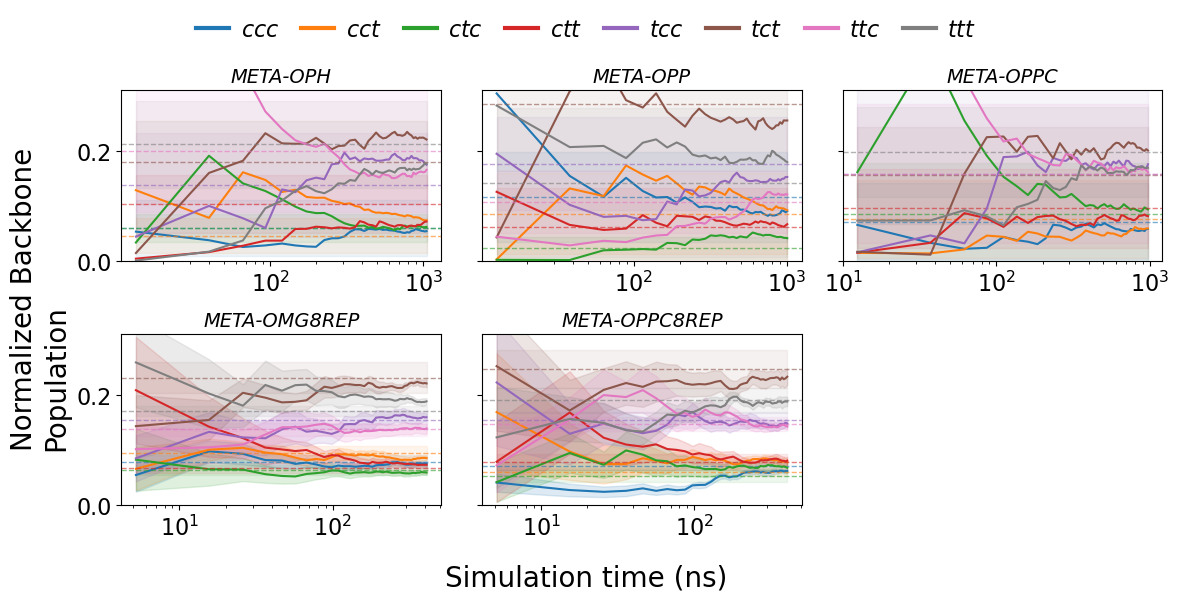

In [26]:
from plotting_style import STATE_COLORS, STATE_ORDER


def plot_method_grid_population(panels, savepath, ncols=3):
    """panels: list of {"name","times","means","ref_mean","ref_err"} dicts, optionally
    with "stds" (means/stds shape (8, T)). One panel per method/CV variant; the 8
    conformer states are overlaid as separate curves colored by STATE_COLORS, plus
    each state's own late-block reference drawn as a dashed horizontal line -- the
    real-simulation-time analogue of plot_method_grid in
    stationary_population_8_conform.ipynb (which plots MSM lag time on the x-axis)."""
    nrows = -(-len(panels) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows), sharey=True)
    axes = np.atleast_1d(axes).flatten()

    for idx, panel in enumerate(panels):
        ax = axes[idx]
        times = panel["times"]
        stds = panel.get("stds")
        for state, state_label in enumerate(STATE_ORDER):
            color = STATE_COLORS[state_label]
            mean = panel["means"][state]
            ax.plot(times, mean, color=color, label=fr"$\mathit{{{state_label}}}$", linewidth=LINEWIDTH)
            if stds is not None:
                std = stds[state]
                ax.fill_between(times, mean - std, mean + std, color=color, alpha=0.15)

            ref_mean = panel["ref_mean"][state]
            ref_err = panel["ref_err"][state]
            ax.axhline(y=ref_mean, linestyle='--', color=color, alpha=0.6, linewidth=1.0)
            ax.fill_between([times.min(), times.max()], [ref_mean - ref_err] * 2, [ref_mean + ref_err] * 2,
                             color=color, alpha=0.08)

        ax.set_xscale("log")
        ax.set_ylim(0, 0.31)
        style_panel(ax, panel["name"], tick_fontsize=16, title_fontsize=TITLE_FONTSIZE)

    for idx in range(len(panels), len(axes)):
        axes[idx].axis("off")

    fig.supxlabel("Simulation time (ns)", fontsize=20)
    fig.supylabel("Normalized Backbone\nPopulation", fontsize=20)

    handles, labels = axes[0].get_legend_handles_labels()
    leg = fig.legend(
        handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.0), ncol=8,
        frameon=False, handlelength=1.5, handletextpad=0.5, columnspacing=1.0, fontsize=16,
    )
    for line in leg.get_lines():
        line.set_linewidth(3.0)

    plt.tight_layout(rect=[0, 0, 1, 0.91])
    plt.savefig(savepath, dpi=300, bbox_inches='tight')
    plt.show()


meta_panels_population = [
    {"name": "META-OPH", **single_replica_meta_pop["META-OPH"]},
    {"name": "META-OPP", **single_replica_meta_pop["META-OPP"]},
    {"name": "META-OPPC", **single_replica_meta_pop["META-OPPC"]},
    {"name": "META-OMG8REP", "times": omg_times_ns, "means": omg_population_mean, "stds": omg_population_std,
     "ref_mean": omg8rep_trans_refer_array, "ref_err": omg8rep_trans_refer_err_array},
    {"name": "META-OPPC8REP", "times": oppc_times_ns, "means": oppc_population_mean, "stds": oppc_population_std,
     "ref_mean": oppc8rep_trans_refer_array, "ref_err": oppc8rep_trans_refer_err_array},
]

plot_method_grid_population(meta_panels_population, "fig/SI_population_8conform_metadynamics_only.png")

## SI: methods-wise view, all 9 methods

The methods-wise companion to the main-text conformation-wise grid above
(`fig/main_population_over_time_all_8_conform_log_scale_esms.png` +
`..._plainmd.png`), covering all 9 methods in the `methods` dict (6 canonical
+ the 3 SI-only single-replica PBMetaD CVs), not just the 5-CV
metadynamics-only subset plotted just above. Reuses `plot_method_grid_population`
(defined above), building its `panels` input directly from `methods` (same
"2d"/"1d" time-axis handling as `plot_population_grid`/`plot_population_grid_refs`).

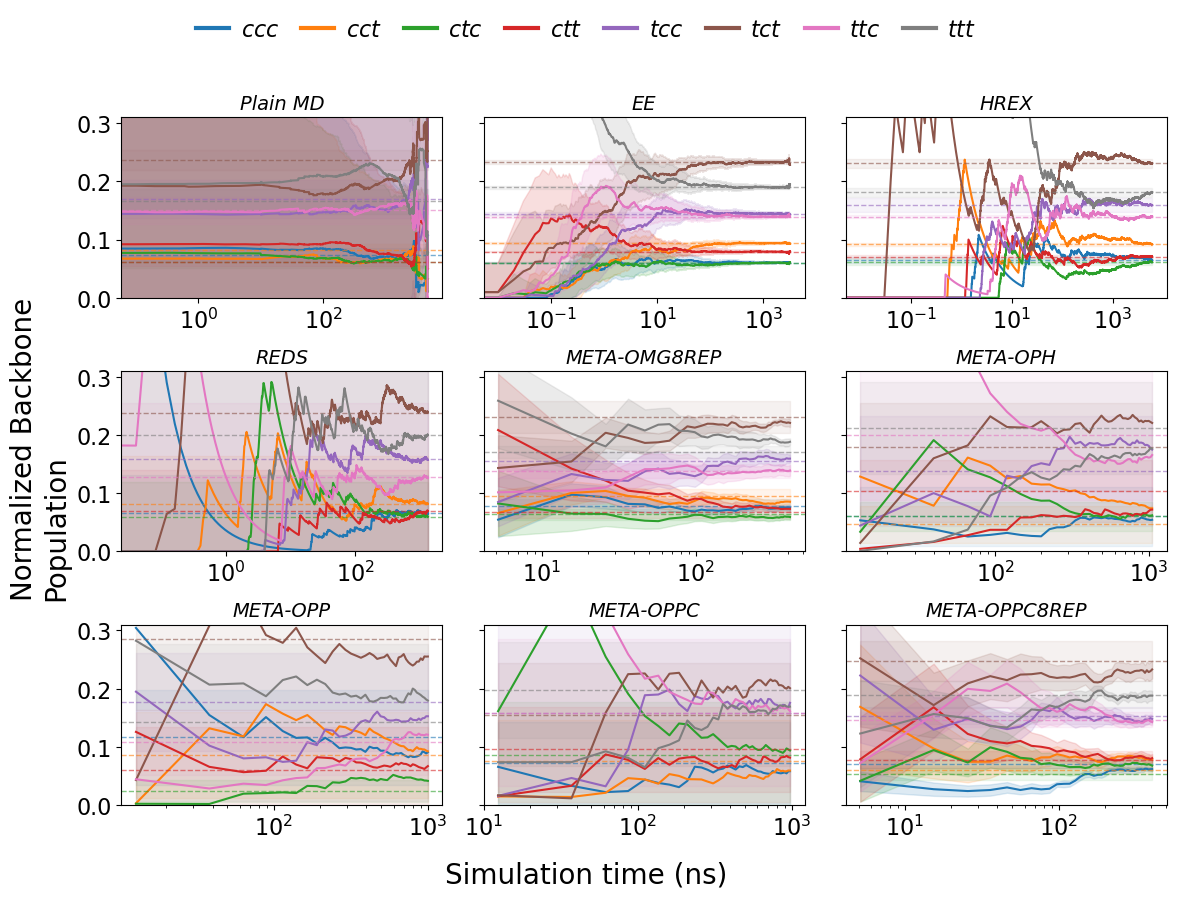

In [27]:
from plotting_style import METHOD_ORDER


def _panel_from_method(name, data):
    if data["shape"] == "2d":
        T = data["mean"].shape[1]
        times = np.arange(T) * data["dt"]
    else:
        times = np.array(data["frames"]) * data["dt"]

    ref_mean = data.get("ref")
    ref_err = data.get("ref_err")
    if ref_mean is not None:
        ref_mean = np.asarray(ref_mean).reshape(-1)
        ref_err = np.asarray(ref_err).reshape(-1)
    else:
        # META-OMG8REP/META-OPPC8REP carry their late-block reference separately
        # (drawn in the metadynamics-only panel above); fall back to it here too.
        ref_mean = {"META-OMG8REP": omg8rep_trans_refer_array, "META-OPPC8REP": oppc8rep_trans_refer_array}[name]
        ref_err = {"META-OMG8REP": omg8rep_trans_refer_err_array, "META-OPPC8REP": oppc8rep_trans_refer_err_array}[name]

    return {
        "name": name, "times": times, "means": data["mean"], "stds": data["std"],
        "ref_mean": ref_mean, "ref_err": ref_err,
    }


all_method_panels_population = [_panel_from_method(name, methods[name]) for name in METHOD_ORDER if name in methods]
plot_method_grid_population(all_method_panels_population, "fig/SI_population_8conform_by_method.png")